# student-performance dataset

In [6]:
!pip install kagglehub
import kagglehub

# Download latest version
path = kagglehub.dataset_download("nikhil7280/student-performance-multiple-linear-regression")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\shali\.cache\kagglehub\datasets\nikhil7280\student-performance-multiple-linear-regression\versions\1


In [42]:
path

'C:\\Users\\shali\\.cache\\kagglehub\\datasets\\nikhil7280\\student-performance-multiple-linear-regression\\versions\\1'

In [43]:
import pandas as pd
import numpy as np
import os
print(os.listdir(path))

['Student_Performance.csv']


In [44]:
for dirpath, dirnames, filenames in os.walk(path):
    print(f"Folder: {dirpath} has {len(filenames)} files")

Folder: C:\Users\shali\.cache\kagglehub\datasets\nikhil7280\student-performance-multiple-linear-regression\versions\1 has 1 files


# EDA

In [46]:
df = pd.read_csv(os.path.join(path, 'Student_Performance.csv'))

In [47]:
df

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0
...,...,...,...,...,...,...
9995,1,49,Yes,4,2,23.0
9996,7,64,Yes,8,5,58.0
9997,6,83,Yes,8,5,74.0
9998,9,97,Yes,7,0,95.0


In [48]:
df

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0
...,...,...,...,...,...,...
9995,1,49,Yes,4,2,23.0
9996,7,64,Yes,8,5,58.0
9997,6,83,Yes,8,5,74.0
9998,9,97,Yes,7,0,95.0


In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


In [50]:
df.dtypes

Hours Studied                         int64
Previous Scores                       int64
Extracurricular Activities           object
Sleep Hours                           int64
Sample Question Papers Practiced      int64
Performance Index                   float64
dtype: object

In [51]:
df.shape

(10000, 6)

In [52]:
#checking for duplicates
df.isnull().sum()

Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

In [53]:
df.duplicated().sum()

127

In [54]:
df['Performance Index'].value_counts()


Performance Index
67.0     187
45.0     185
56.0     181
49.0     181
40.0     180
        ... 
14.0       7
99.0       6
11.0       5
100.0      3
10.0       1
Name: count, Length: 91, dtype: int64

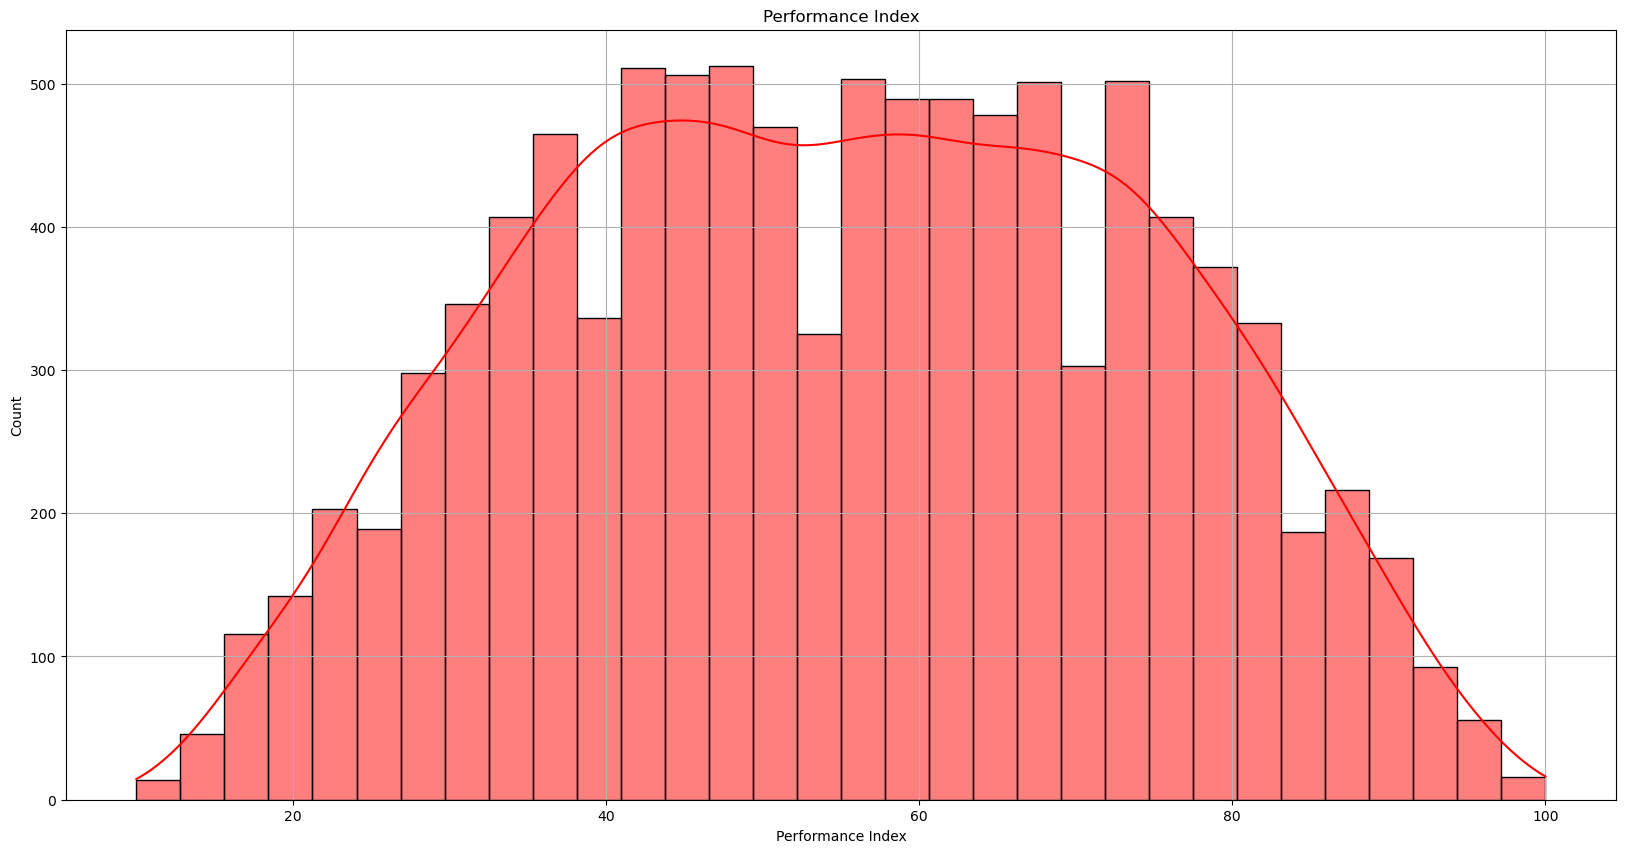

In [55]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(20,10))
sns.histplot(x=df["Performance Index"],kde=True,color="red")
plt.title("Performance Index")
plt.grid(True)
plt.show()

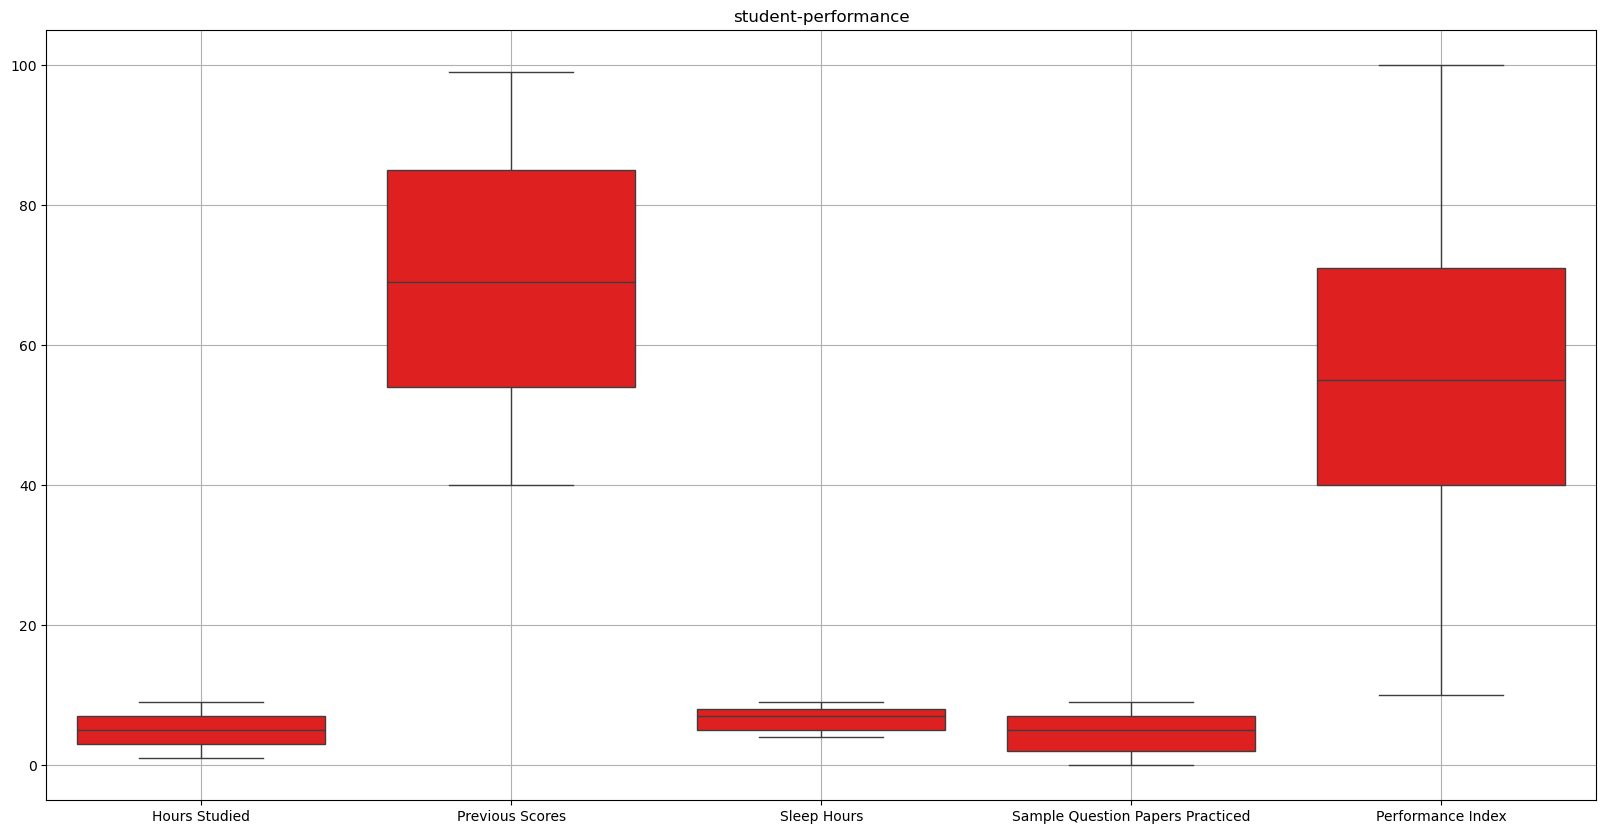

In [56]:
plt.figure(figsize=(20,10))
sns.boxplot(data=df,color="red")
plt.title("student-performance")
plt.grid(True)
plt.show()

# Correlation matrix

In [58]:
# convert object to number for the correlation matrix
df["Extracurricular Activities"] = df["Extracurricular Activities"].map({"Yes": 1, "No": 0})

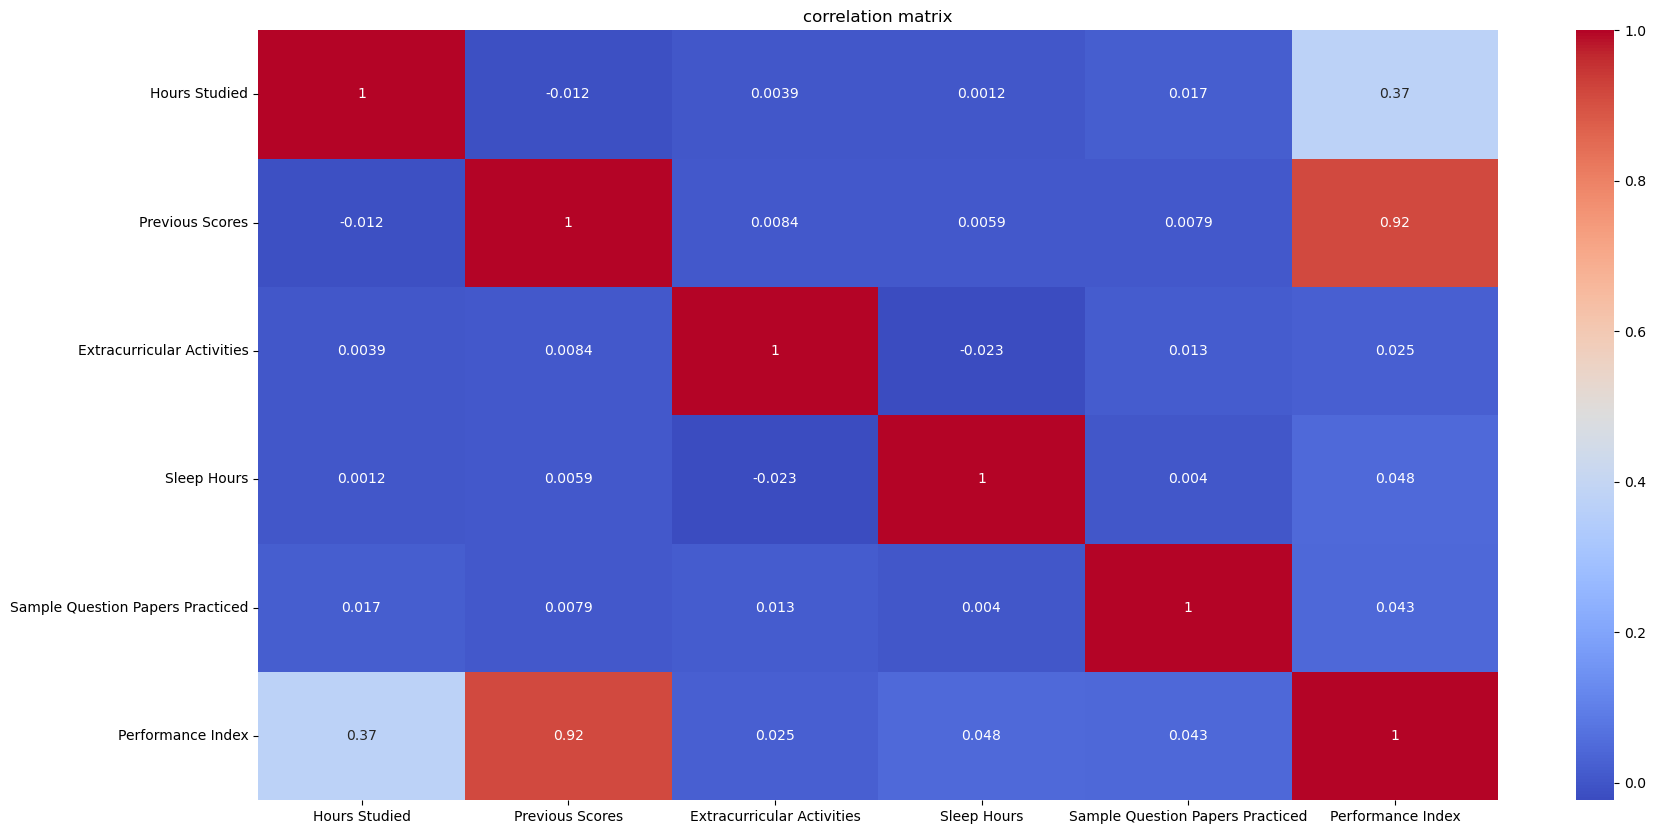

In [59]:
# correlation matrix
plt.figure(figsize=(20,10))
sns.heatmap(df.corr(),annot=True,cmap="coolwarm")
plt.title("correlation matrix")
plt.show()

# Feature engineering

In [60]:
# 1. Total study effort 
df["study_effort"] = df["Hours Studied"] + df["Sample Question Papers Practiced"]

# 2. Study efficiency
df["efficiency"] = df["Previous Scores"] / df["Hours Studied"]

# 3. Sleep quality category
df["sleep_category"] = pd.cut(df["Sleep Hours"], 
                               bins=[0, 5, 7, 9], 
                               labels=["low", "medium", "high"])

# 4. High achiever in previous scores
df["high_prev_score"] = (df["Previous Scores"] > 70).astype(int)

In [61]:
df.dtypes

Hours Studied                          int64
Previous Scores                        int64
Extracurricular Activities             int64
Sleep Hours                            int64
Sample Question Papers Practiced       int64
Performance Index                    float64
study_effort                           int64
efficiency                           float64
sleep_category                      category
high_prev_score                        int32
dtype: object

In [62]:
df

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index,study_effort,efficiency,sleep_category,high_prev_score
0,7,99,1,9,1,91.0,8,14.142857,high,1
1,4,82,0,4,2,65.0,6,20.500000,low,1
2,8,51,1,7,2,45.0,10,6.375000,medium,0
3,5,52,1,5,2,36.0,7,10.400000,low,0
4,7,75,0,8,5,66.0,12,10.714286,high,1
...,...,...,...,...,...,...,...,...,...,...
9995,1,49,1,4,2,23.0,3,49.000000,low,0
9996,7,64,1,8,5,58.0,12,9.142857,high,0
9997,6,83,1,8,5,74.0,11,13.833333,high,1
9998,9,97,1,7,0,95.0,9,10.777778,medium,1


# data preprocessing

In [64]:
# Count how many duplicates
print(df.duplicated().sum())

# Show duplicates including the first occurrence
df[df.duplicated(keep=False)]

df = df.drop_duplicates()
print("Rows after removing duplicates:", len(df))

127
Rows after removing duplicates: 9873


In [65]:
# dataset after deleting the rows. now there are 9873 rows
df

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index,study_effort,efficiency,sleep_category,high_prev_score
0,7,99,1,9,1,91.0,8,14.142857,high,1
1,4,82,0,4,2,65.0,6,20.500000,low,1
2,8,51,1,7,2,45.0,10,6.375000,medium,0
3,5,52,1,5,2,36.0,7,10.400000,low,0
4,7,75,0,8,5,66.0,12,10.714286,high,1
...,...,...,...,...,...,...,...,...,...,...
9995,1,49,1,4,2,23.0,3,49.000000,low,0
9996,7,64,1,8,5,58.0,12,9.142857,high,0
9997,6,83,1,8,5,74.0,11,13.833333,high,1
9998,9,97,1,7,0,95.0,9,10.777778,medium,1


In [66]:
# renaming performance index to target 
df= df.rename(columns={"Performance Index":"target"})

In [67]:
df

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,target,study_effort,efficiency,sleep_category,high_prev_score
0,7,99,1,9,1,91.0,8,14.142857,high,1
1,4,82,0,4,2,65.0,6,20.500000,low,1
2,8,51,1,7,2,45.0,10,6.375000,medium,0
3,5,52,1,5,2,36.0,7,10.400000,low,0
4,7,75,0,8,5,66.0,12,10.714286,high,1
...,...,...,...,...,...,...,...,...,...,...
9995,1,49,1,4,2,23.0,3,49.000000,low,0
9996,7,64,1,8,5,58.0,12,9.142857,high,0
9997,6,83,1,8,5,74.0,11,13.833333,high,1
9998,9,97,1,7,0,95.0,9,10.777778,medium,1


# Encoding

In [69]:
df = pd.get_dummies(df, columns=["sleep_category"])

In [70]:
df

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,target,study_effort,efficiency,high_prev_score,sleep_category_low,sleep_category_medium,sleep_category_high
0,7,99,1,9,1,91.0,8,14.142857,1,False,False,True
1,4,82,0,4,2,65.0,6,20.500000,1,True,False,False
2,8,51,1,7,2,45.0,10,6.375000,0,False,True,False
3,5,52,1,5,2,36.0,7,10.400000,0,True,False,False
4,7,75,0,8,5,66.0,12,10.714286,1,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,1,49,1,4,2,23.0,3,49.000000,0,True,False,False
9996,7,64,1,8,5,58.0,12,9.142857,0,False,False,True
9997,6,83,1,8,5,74.0,11,13.833333,1,False,False,True
9998,9,97,1,7,0,95.0,9,10.777778,1,False,True,False


# train test split

In [72]:
from sklearn.model_selection import train_test_split

# Features and target
x = df.drop(columns=["target"])
y = df["target"]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

print("X_train:", x_train.shape)
print("X_test:", x_test.shape)

X_train: (7898, 11)
X_test: (1975, 11)


# feature scaling

In [74]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

print("scaling done")


scaling done


# Model Training & Evaluation

In [76]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import ExtraTreesRegressor
from xgboost import XGBRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=1.0),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Extra Trees": ExtraTreesRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42),
}

for name, model in models.items():
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2   = r2_score(y_test, y_pred)
    print(f"{name:25} → RMSE: {rmse:.2f}  |  R²: {r2:.2f}")

Linear Regression         → RMSE: 2.07  |  R²: 0.99
Ridge                     → RMSE: 2.07  |  R²: 0.99
Lasso                     → RMSE: 2.76  |  R²: 0.98
Random Forest             → RMSE: 2.38  |  R²: 0.98
Extra Trees               → RMSE: 2.62  |  R²: 0.98
Gradient Boosting         → RMSE: 2.14  |  R²: 0.99
XGBoost                   → RMSE: 2.28  |  R²: 0.99


## here LinearRegression, Ridge, GradientBoostingRegressor, XGBRegressor are well performing with 99% R2


# graph

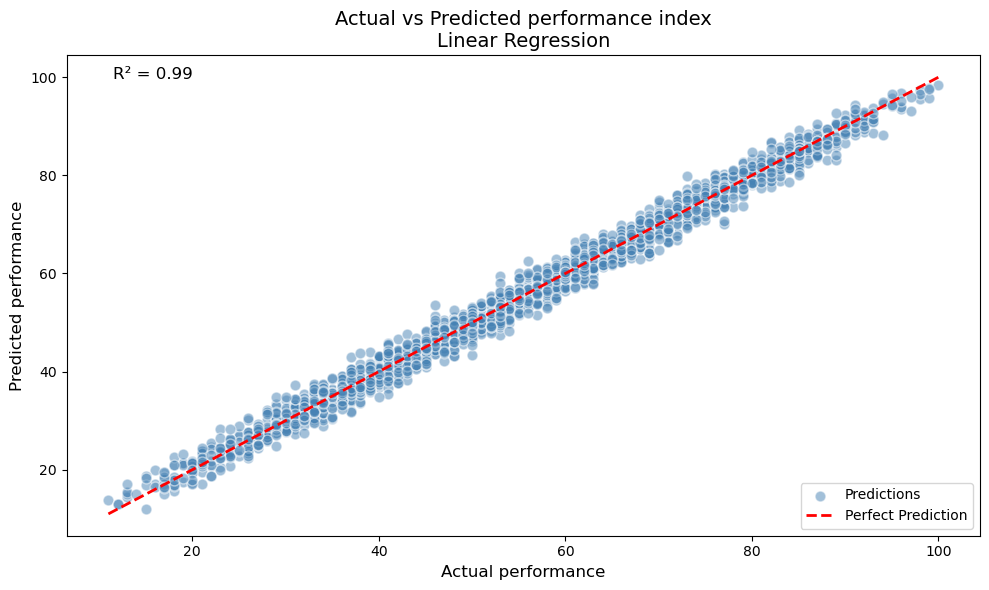

In [110]:
y_pred = models["Linear Regression"].predict(x_test)   

plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color="steelblue", edgecolors="white", s=60, label="Predictions")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", linewidth=2, linestyle="--", label="Perfect Prediction")

r2 = r2_score(y_test, y_pred)
plt.text(0.05, 0.95, f"R² = {r2:.2f}", transform=plt.gca().transAxes, fontsize=12, color="black")

plt.xlabel("Actual performance", fontsize=12)
plt.ylabel("Predicted performance", fontsize=12)
plt.title("Actual vs Predicted performance index\nLinear Regression", fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()